# 🎯 [TRN01] 드론 시뮬레이터 비행로그 기반 숙련도 분석기
### Google Colab 실습 환경 (교육·훈련 / Level 3)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/edunlab/milicontent2/blob/main/uploads/TRN01/trn01_m10_solution.ipynb)

---

## 📌 1. 프로젝트 개요 및 학습 목표

| 항목 | 내용 |
| :--- | :--- |
| **과정 분류** | 교육·훈련 (Level 3) |
| **학습 소요 시간** | 10개 미션 (5일 / 총 27.5시간) |
| **환경 사양** | Python 3.10+, numpy, pandas, matplotlib, scipy, scikit-learn |

### 📖 프로젝트 학습 목표 및 대상자
러시아-우크라이나 전쟁에서 소형 드론 조종 인력을 단기간에 양성·평가해야 했던 전장 요구를 배경으로, 교육용 가상 비행로그를 직접 생성·분석하며 드론 숙련도 평가 파이프라인 전 주기를 설계·구현하는 프로젝트다. 최종 목표는 교관 평가와 정합성을 갖춘 객관적 지표와 개인별 피드백을 산출하되, 등급과 재교육 결정은 교관이 근거를 기록해 확정하는 신뢰 가능한 분석기를 완성하는 것이다.

#### 본 프로젝트를 통해 익히는 핵심 역량

- **전술 시계열 데이터 설계 및 정제 역량:** 비행로그 스키마와 보안(가명화) 규칙을 정의하고, PWM 정규화·Hampel 필터·보간으로 센서 잡음과 단절을 복구하는 실무 기법을 익힌다.
- **도메인 기반 숙련도 모델링 및 한계 분석 역량:** 경로·호버링 Baseline 채점부터 장애물 회피·비상 착륙 반응 기반 정밀 평가 엔진까지 단계적으로 고도화하며, 혼동표·오탐 분석으로 모델의 사각지대를 찾아내는 방법을 습득한다.
- **통계적 신뢰도 검증 및 조작 습관 진단 역량:** 단발성 점수의 오류를 줄이기 위해 다회차 비행 묶음 평가와 부트스트랩 신뢰구간을 적용하고, 급조작·과보정 등 개인별 습관을 정량적으로 판별하는 원리를 익힌다.
- **HITL(인간-중심) 거버넌스 및 시스템 복원력 설계 역량:** 저신뢰·고위험 사례 우선 검토, 2단계 교관 확인, 해시 체인 감사 로그로 AI 책임 분계를 구현하고, 대량 배치 스트레스 시험과 AAR 재튜닝으로 운용 안정성을 확보하는 역량을 기른다.

#### 추천 학습 대상자 (페르소나)

- **드론·무인기 교육훈련 교관 및 평가 담당자:** 시뮬레이터 비행로그를 정량 지표로 해석하고, 교관의 경험적 평가와 AI 분석 결과를 결합해 개인별 맞춤 피드백·재교육 기준을 정립하고자 하는 현장 실무자.
- **국방 AI·데이터 분석 실무자 및 개발자:** Python 기본 문법을 바탕으로 시계열 노이즈 전처리, 다중 지표 채점 모델링, 부트스트랩 신뢰도 산출, HITL 승인 워크플로우까지 End-to-End 분석 파이프라인을 직접 구현하려는 개발자.
- **무인체계 시뮬레이터·훈련체계 기획 및 품질 검증 담당자:** 로그 스키마 표준화, 대량 배치 스트레스 테스트, 사후강평(AAR) 기반 파라미터 재튜닝, 감사 로그 거버넌스 등 신뢰 가능한 AI 보조 평가 체계의 설계 기준을 익히려는 엔지니어.


In [1]:
# ============================================================================
# [Google Colab 환경 설정] 필수 라이브러리 설치 및 임포트
# ============================================================================
!pip install -q numpy pandas matplotlib scipy scikit-learn

import os
import sys
import time
import math
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 그래프 영문 폰트 기본 설정 (환경 독립성 보장)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

print(f"실행 환경 준비 완료 (Python {sys.version.split()[0]})")


실행 환경 준비 완료 (Python 3.14.10)


---

## 🎯 미션 10. 드론 비행로그 숙련도 분석 시스템 통합 및 교육훈련 브리핑 패키지 완성
**소요시간**: 약 3.5시간 | **필수 산출물**: src/main_trn01.py, README.md, docs/trn01_final_report.pdf(md) (필수)

### 📋 미션 개요 (Overview)
앞선 9개 미션에서 구현한 스키마 검증, 전처리, 정밀 채점·습관 분석, HITL 검토, 대시보드, 재튜닝 파라미터를 하나의 운용 가능한 시스템으로 통합한다. 본 미션에서는 신규 기수 로그를 일괄 처리하고 손상 로그 격리 및 자체 점검 항목 전수 통과를 확인하는 통합 진입점(`main_trn01.py`)을 완성한다. 최종 결과와 재교육 검토 대상, 시스템 한계 및 확장 방향을 담은 5분 분량 교육훈련 브리핑 패키지와 배포 문서(`README.md`, `trn01_final_report`)를 마무리한다.

### 🎓 학습 목표 (Objectives)
개별 미션으로 개발한 모듈들을 **재현 가능한 단일 파이프라인으로 통합하고, 기술 지표와 운용 한계를 의사결정자에게 명확히 전달하는 최종 패키징 역량**을 익힌다. 손상 로그 격리·등급 일치율·위험 탐지·HITL·코드 커버리지 등 종단 간(E2E) 자체 점검 기준을 검증하는 방법과, 재교육 검토 대상·운용 유의사항·확장 방향을 5분 브리핑 및 배포 문서로 구조화하는 실무 능력을 완성한다.

### 🛠️ 단계별 수행 및 AI 활용 가이드
#### Step 1. 미션10 코드를 실행해 자체 점검 항목이 모두 PASS인지 확인한다.
#### 이 단계의 역할
미션10 코드를 실행해 자체 점검 항목이 모두 PASS인지 확인한다.

#### 해야 할 일

- 미션10 코드를 실행해 자체 점검 항목이 모두 PASS인지 확인한다.에 필요한 데이터셋과 입력 파라미터를 준비한다.
- 정답 코드 및 모듈을 실행하여 중간 출력 결과를 도출한다.
- 출력된 지표와 로그가 기준 조건을 만족하는지 대조·검증한다.

#### 핵심 확인 지표
> ( )

#### 학습자가 제출해야 하는 내용

- 미션10 코드를 실행해 자체 점검 항목이 모두 PASS인지 확인한다. 실행 결과 및 검증 로그

#### AI 활용 가이드 (프롬프트 예시 & 검증 포인트)
**AI 질의 예시**

> 미션1~미션9 모듈과 재튜닝 파라미터를 main_trn01.py로 통합하고, 로그 유실·결측·등급 일치율·위험 탐지 재현율·처리 지연·AI 단독 확정 0건·커버리지 자체 점검을 자동 실행해줘.
**AI 응답 검증 포인트**

- 자체 점검 체크리스트 전 항목이 실제 실행 결과로 PASS 판정을 받았는지 로그로 확인
- 하드코딩된 임시 경로 없이 설정 파일(YAML)과 상대 경로로 재현 가능하게 실행되는지 점검

#### Step 2. 손상 로그 2건이 격리된 것을 확인한다.
#### 이 단계의 역할
손상 로그 2건이 격리된 것을 확인한다.

#### 해야 할 일

- 손상 로그 2건이 격리된 것을 확인한다.에 필요한 데이터셋과 입력 파라미터를 준비한다.
- 정답 코드 및 모듈을 실행하여 중간 출력 결과를 도출한다.
- 출력된 지표와 로그가 기준 조건을 만족하는지 대조·검증한다.

#### 핵심 확인 지표
> ( )

#### 학습자가 제출해야 하는 내용

- 손상 로그 2건이 격리된 것을 확인한다. 실행 결과 및 검증 로그

#### AI 활용 가이드 (프롬프트 예시 & 검증 포인트)
**AI 질의 예시**

> 신규 기수 통합 실행 시 의도적으로 포함된 손상 로그 2건이 파이프라인을 중단시키지 않고 사유와 함께 격리 폴더/리포트로 분리되는지 검증하는 코드를 확인해줘.
**AI 응답 검증 포인트**

- 손상 로그 2건 외 나머지 정상 로그의 채점·등급·HITL 대기열 등록이 모두 정상 완료됐는지 확인
- 격리 리포트에 기록된 파일명/세션 ID와 사유가 실제 손상 내용과 일치하는지 대조

#### Step 3. 출력된 브리핑 요약을 바탕으로 5분 분량 교육훈련 브리핑 자료를 만든다.
#### 이 단계의 역할
출력된 브리핑 요약을 바탕으로 5분 분량 교육훈련 브리핑 자료를 만든다.

#### 해야 할 일

- 출력된 브리핑 요약을 바탕으로 5분 분량 교육훈련 브리핑 자료를 만든다.에 필요한 데이터셋과 입력 파라미터를 준비한다.
- 정답 코드 및 모듈을 실행하여 중간 출력 결과를 도출한다.
- 출력된 지표와 로그가 기준 조건을 만족하는지 대조·검증한다.

#### 핵심 확인 지표
> ( )

#### 학습자가 제출해야 하는 내용

- 출력된 브리핑 요약을 바탕으로 5분 분량 교육훈련 브리핑 자료를 만든다. 실행 결과 및 검증 로그

#### AI 활용 가이드 (프롬프트 예시 & 검증 포인트)
**AI 질의 예시**

> 통합 실행 결과 요약(기수 숙련도 분포, 재교육 검토 대상, 시스템 한계, 향후 확장 방향)을 바탕으로 교관·지휘관 대상 5분 분량 교육훈련 브리핑 자료 초안을 작성해줘.
**AI 응답 검증 포인트**

- 브리핑 자료의 모든 수치(일치율, 재교육 검토 인원, 처리량 등)가 main_trn01.py 실제 출력과 일치하는지 확인
- AI의 한계와 HITL 최종 결정 원칙이 왜곡 없이 명확히 전달되는지 점검

#### Step 4. 도전 과제 및 파라미터 튜닝 최적화
#### 이 단계의 역할
기본 파이프라인 수행 후 심화 튜닝 및 조건 변경을 통해 최적화 역량을 다진다.

#### 해야 할 일
CONFIG의 ridge_alpha를 0.1로 바꾸고 make_dataset 대신 주간 자료만으로 엔진을 맞춰 실행한 뒤 재튜닝값과의 차이를 브리핑에 추가한다.

#### 학습자가 제출해야 하는 내용

- 파라미터 변경 전후 비교 분석 메모 및 최종 최적화 결과

#### AI 활용 가이드 (프롬프트 예시 & 검증 포인트)
**AI 질의 예시**

> 배포용 README.md에 설치·실행 방법, 폴더 구조, 설정 파라미터 변경법, 장애 대응(트러블슈팅) 가이드를 정리하고, 신규 기수 추가 시나리오를 점검해줘.
**AI 응답 검증 포인트**

- README.md의 실행 명령어와 파일 경로가 실제 프로젝트 구조(src/, configs/, docs/)와 100% 일치하는지 확인
- 처음 프로젝트를 접하는 실무자가 README만 보고도 통합 실행을 재현할 수 있는지 점검


[PASS] 손상 로그 2건 격리
[PASS] 로그 유실 0건(채점+격리=전체)
[PASS] 전처리 후 결측 0
[PASS] 비행별 등급 일치율 75% 이상
[PASS] 조종자 등급 일치율 85% 이상
[PASS] 위험 사건 탐지 재현율 85% 이상
[PASS] 로그당 처리 200ms 이내
[PASS] AI 확정 0건(전부 교관 대기)
[PASS] 감사 로그 건수 일치
[PASS] 함수 커버리지 85% 이상
자체 점검 10/10 통과, 함수 커버리지 92%, 파이프라인 실행 성공 예
조종자 등급 분포: {'A': 4, 'B': 15, 'C': 11} / 신뢰도: {'High': 21, 'Medium': 6, 'Low': 3}

[교육훈련 브리핑 요약 - 교육용가상자료]
1. 처리: 비행로그 90건 중 88건 분석, 손상 2건 격리, 로그당 10.6 ms, 전체 5.7s
2. 성능: 비행별 등급 일치율 79.5%, 조종자 등급 일치율 93.3%, 위험 사건 탐지 재현율 97.4%
3. 결과: A 4명 / B 15명 / C 11명(재교육 검토 대상 P001, P007, P012, P015, P016 외), 전원 교관 검토 대기
4. 운용 유의: AI 등급은 교관 판단 보조 자료이며, 재교육·자격 보류는 교관 근거 기록과 두 번째 교관 확인 후 확정한다.
5. 한계·확장: 가상 시뮬레이터 로그 기준 결과다. 실제 시뮬레이터 로그 형식에 맞춘 재검증이 필요하며, 훈련 관리 체계와는 결과 조회 API로 연동한다.
[산출물 저장 완료] src/main_trn01.py, README.md, docs/trn01_final_report.md


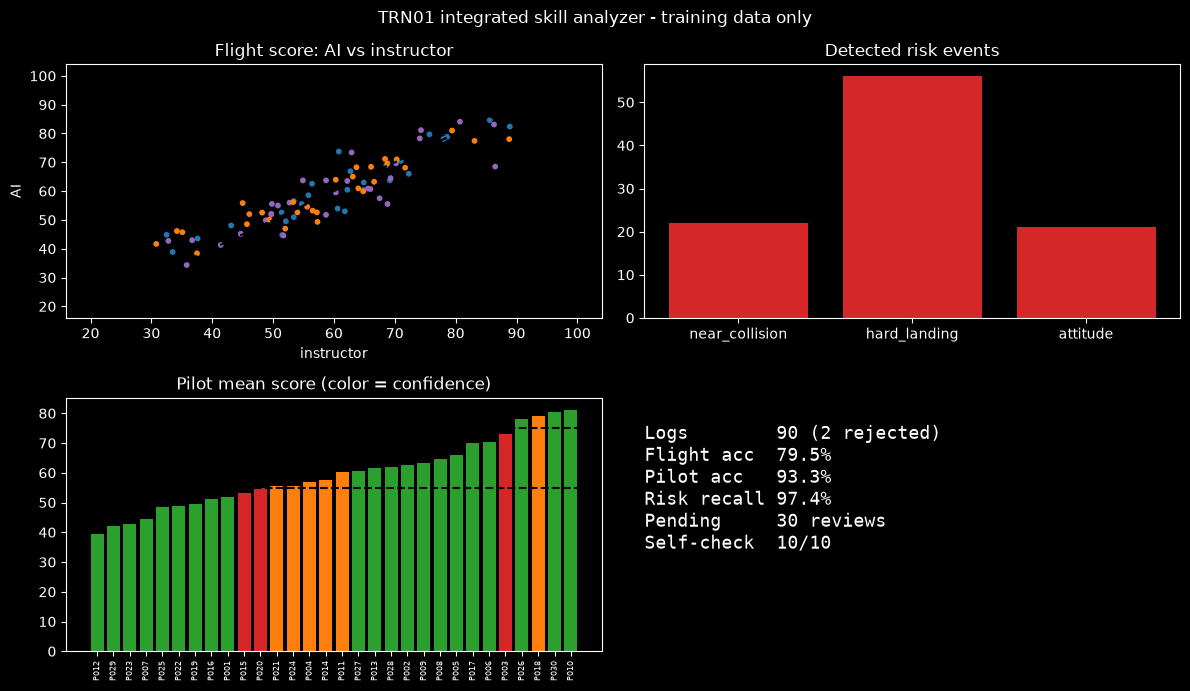

In [2]:
"""비행로그 검증·전처리부터 특징 추출, 재튜닝된 숙련도 엔진, 위험 조작 탐지, 조종자별 등급·신뢰도, 교관 HITL 검토 대기열, 분석 대시보드까지 전체 파이프라인을 한 파일로 통합 실행하고, 함수 커버리지를 포함한 자체 점검 결과와 교육훈련 브리핑 요약을 출력한다."""
import hashlib
import inspect
import json
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

# ---------------------------------------------------------------------------
# [교육용가상자료] 드론 조종 시뮬레이터 비행로그 생성기 (실제 훈련생·장비 정보 없음, 조종자는 가명 P001~)
# 비행 1회 = 120초(10Hz): 경로 비행(0~60초) -> 호버링(60~85초) -> 돌발 장애물 회피(85초) -> 비상 착륙(100초 지시)
# 조종자마다 숨은 숙련도(skill)와 조작 습관(급조작 jerky, 과보정 overcorr)이 있고, 교관 점수는 이를 반영해 만든다.
# ---------------------------------------------------------------------------
DT, STEPS = 0.1, 1200
T = np.arange(STEPS) * DT
COND = {"day": dict(wind=0.4, gust=0.0, gps=0.25, delay=0.0), "night": dict(wind=0.4, gust=0.0, gps=0.5, delay=0.15),
        "gust": dict(wind=1.2, gust=2.5, gps=0.25, delay=0.0)}
OBST_T, LAND_T = 85.0, 100.0


def make_pilots(n=40, seed=7):
    rng = np.random.default_rng(seed)
    skill = rng.beta(2.2, 2.0, n)
    return pd.DataFrame({"pilot": [f"P{i + 1:03d}" for i in range(n)], "skill": skill,
                         "jerky": rng.random(n) < 0.15 + 0.35 * (1 - skill), "overcorr": rng.random(n) < 0.15 + 0.35 * (1 - skill)})


def target_path(t):
    """사각형 경로(40x30m, 고도 20m)를 3m/s로 비행 -> 60초 지점에서 호버링 -> 착륙 지시 후 고도 0."""
    s = np.minimum(t, 60.0) * 3.0 % 140.0
    x = np.select([s < 40, s < 70, s < 110], [s, 40.0, 40 - (s - 70)], 0.0)
    y = np.select([s < 40, s < 70, s < 110], [0.0, s - 40, 30.0], 30 - (s - 110))
    z = np.where(t >= LAND_T, 0.0, 20.0)
    return np.stack([x, y, z], -1)


def fly(pilots, cond="day", seed=0, delay_extra=0.0, obstacle_side=None):
    """여러 조종자의 비행 1회를 동시에 모의한다(벡터화). 반환: 로그 배열 dict, 비행별 정답 정보 DataFrame."""
    rng = np.random.default_rng(seed)
    c = COND[cond]
    delay_extra = delay_extra + c["delay"]
    n = len(pilots)
    sk, jk, oc = pilots["skill"].values, pilots["jerky"].values, pilots["overcorr"].values
    gain = (0.5 + 1.2 * sk) * np.where(oc, 1.5, 1.0)
    damp = np.where(oc, 0.25, 0.6 + 0.3 * sk)
    noise = 0.03 + 0.35 * (1 - sk)
    smooth = np.where(jk, 0.25, 0.75)
    delay = np.round((0.25 + 0.35 * (1 - sk) + delay_extra) / DT).astype(int)
    rt_obs = np.clip(0.5 + 1.5 * (1 - sk) + rng.normal(0, 0.2, n) + delay_extra, 0.3, 3.5)
    h_flare = np.clip(0.8 + 5.0 * sk - 1.5 * oc + rng.normal(0, 0.4, n), 0.3, None)
    side = rng.choice([-1, 1], n) if obstacle_side is None else np.full(n, obstacle_side)
    pos = np.tile(target_path(np.zeros(1))[0], (n, 1)).astype(float); vel = np.zeros((n, 3)); stick = np.zeros((n, 3))
    hist = np.zeros((STEPS, n, 3)); P = np.zeros((STEPS, n, 3)); S = np.zeros((STEPS, n, 3)); ATT = np.zeros((STEPS, n, 2))
    tgt_all = np.zeros((STEPS, n, 3)); vz_touch = np.full(n, np.nan); landed = np.zeros(n, bool)
    vmax = np.array([5.0, 5.0, 3.0])
    gust = np.zeros((n, 2))
    for i, t in enumerate(T):
        tgt = np.tile(target_path(np.array([t]))[0], (n, 1))
        if t >= OBST_T:                                              # 장애물: 6m 옆으로 회피해야 함(조종자는 반응시간 이후 인지)
            tgt_all[i] = tgt + np.c_[np.zeros(n), side * 6.0, np.zeros(n)]
            tgt[:, 1] += np.where(t >= OBST_T + rt_obs, side * 6.0, 0.0)
        else:
            tgt_all[i] = tgt
        hist[i] = pos
        seen = hist[np.maximum(i - delay, 0), np.arange(n)]          # 반응 지연만큼 늦게 본 위치
        cmd = np.clip(gain[:, None] * (tgt - seen) / 4.0 - damp[:, None] * vel / vmax + rng.normal(0, 1, (n, 3)) * noise[:, None], -1, 1)
        if t >= LAND_T:                                              # 비상 착륙: 하강하다가 h_flare 높이에서 감속(숙련자일수록 일찍 감속)
            cmd[:, 2] = np.where(seen[:, 2] > h_flare, -1.0, -0.12 + rng.normal(0, 0.05, n))
        spikes = (jk[:, None] & (rng.random((n, 3)) < 0.02)) * rng.choice([-1, 1], (n, 3)) * 0.9
        stick = np.clip(smooth[:, None] * stick + (1 - smooth[:, None]) * cmd + spikes, -1, 1)
        gust = 0.95 * gust + rng.normal(0, c["gust"] * 0.3, (n, 2))
        wind = np.c_[np.full(n, c["wind"]) + gust[:, 0], gust[:, 1], np.zeros(n)]
        vel += (stick * vmax - vel) * DT / 0.6
        vel[landed] = 0.0
        pos = pos + (vel + wind * (~landed)[:, None]) * DT
        touch = (pos[:, 2] <= 0) & ~landed & (t >= LAND_T)
        vz_touch[touch] = -vel[touch, 2]; landed |= touch
        pos[:, 2] = np.maximum(pos[:, 2], 0.0)
        P[i], S[i] = pos, stick
        ATT[i] = np.c_[stick[:, 1] * 28 + gust[:, 1] * 1.5, -stick[:, 0] * 28 + gust[:, 0] * 1.5]
    g = rng.normal(0, c["gps"], P.shape)
    log = {"t": T, "x": P[..., 0] + g[..., 0], "y": P[..., 1] + g[..., 1], "alt": P[..., 2] + g[..., 2] * 0.5,
           "stick_pitch": S[..., 0], "stick_roll": S[..., 1], "throttle": S[..., 2], "roll_deg": ATT[..., 0], "pitch_deg": ATT[..., 1],
           "tx": tgt_all[..., 0], "ty": tgt_all[..., 1], "talt": tgt_all[..., 2], "true_x": P[..., 0], "true_y": P[..., 1], "true_alt": P[..., 2]}
    k_obs = int((OBST_T + 2.5) / DT)
    lateral = np.abs(P[k_obs, :, 1] - P[int(OBST_T / DT), :, 1])
    truth = pd.DataFrame({"pilot": pilots["pilot"].values, "cond": cond, "skill": sk, "jerky": jk, "overcorr": oc, "rt_obs": rt_obs,
                          "near_collision": lateral < 2.5, "vz_touch": np.round(vz_touch, 2), "hard_landing": np.nan_to_num(vz_touch, nan=3.0) > 1.6,
                          "attitude_exceed": (np.abs(ATT) > 35).any(axis=2).sum(axis=0) >= 10})
    risk = truth[["near_collision", "hard_landing", "attitude_exceed"]].sum(axis=1)
    inst = 40 + 50 * sk - 5 * jk - 5 * oc - 4 * risk + rng.normal(0, 3, n)      # 교관 평가 점수(가상)
    truth["instructor"] = np.clip(inst, 0, 100).round(1)
    truth["grade"] = np.where(truth["instructor"] >= 75, "A", np.where(truth["instructor"] >= 55, "B", "C"))
    return log, truth


def one(log, j):
    """여러 조종자 로그에서 j번째 조종자 1명의 로그(DataFrame)를 꺼낸다."""
    return pd.DataFrame({k: (v if v.ndim == 1 else v[:, j]) for k, v in log.items()})
# ---------------------------------------------------------------------------

# ---- 비행로그 특징 추출 공통 함수(여러 조종자 로그를 한 번에 계산) ----
from scipy.ndimage import uniform_filter1d

BASE_F = ["path_rmse", "hover_drift", "hover_std", "alt_err"]
ADV_F = BASE_F + ["obs_rt", "obs_lateral", "touch_vz", "att_exceed", "jerk", "overshoot", "n_risk"]
RULES = {"near_collision": ("obs_lateral", "<", 2.5), "hard_landing": ("touch_vz", ">", 2.0), "attitude_exceed": ("att_exceed", ">=", 10)}


def detect(df):
    """위험 조작 사건 탐지 규칙: 장애물 2.5초 후 회피 거리 2.5m 미만, 접지 속도 2.0m/s 초과, 자세 35도 초과 1초 이상."""
    out = {}
    for ev, (f, op, th) in RULES.items():
        out[ev] = df[f] < th if op == "<" else (df[f] > th if op == ">" else df[f] >= th)
    return pd.DataFrame(out)


def features(log):
    """경로 이탈도·호버링 안정성(기본) + 장애물 반응·착륙 속도·자세 한계·급조작·과보정(고도화) 특징."""
    X, Y, A = (uniform_filter1d(log[k], 9, axis=0) for k in ("x", "y", "alt"))       # GPS 잡음 완화(이동평균 0.9초)
    h = np.hypot(X - log["tx"], Y - log["ty"])
    cr, hv = slice(0, 600), slice(620, 850)
    k0, k1 = int(OBST_T / DT), int((OBST_T + 2.5) / DT)
    side = np.sign(log["ty"][k0 + 1] - log["ty"][k0 - 1])
    moved = (log["stick_roll"][k0:k0 + 40] * side) > 0.3
    rt = np.where(moved.any(0), moved.argmax(0) * DT, 4.0)
    vz = -np.gradient(A, DT, axis=0)
    land = np.argmax((A < 0.4) & (T[:, None] >= LAND_T), axis=0)
    touch = np.array([vz[max(i - 6, 0):i - 2, j].mean() if i > 6 else 3.0 for j, i in enumerate(land)])
    ds = np.abs(np.diff(np.stack([log["stick_roll"], log["stick_pitch"]]), axis=1)) / DT
    return pd.DataFrame({
        "path_rmse": np.sqrt((h[cr] ** 2).mean(0)), "hover_drift": h[hv].mean(0), "hover_std": np.hypot(X[hv].std(0), Y[hv].std(0)),
        "alt_err": np.abs(A[:850] - log["talt"][:850]).mean(0),
        "obs_rt": rt, "obs_lateral": np.abs(Y[k1] - Y[k0]), "touch_vz": touch,
        "att_exceed": (np.maximum(np.abs(log["roll_deg"]), np.abs(log["pitch_deg"])) > 35).sum(0),
        "jerk": np.percentile(ds, 95, axis=(0, 1)),
        "overshoot": np.clip(np.abs(Y[k0:k0 + 120] - Y[k0]).max(0) - 6.0, 0, None)}).pipe(
        lambda d: d.assign(n_risk=detect(d).sum(axis=1)))                                     # overshoot: 회피 후 목표 6m를 넘어선 거리(과보정)


def make_dataset(n_pilots=40, seed=7, conds=("day", "night", "gust"), flights=1):
    """조종자 n명 x 조건 x 반복 비행 -> 비행별 특징 + 정답(교관 점수·등급·위험 사건) 표."""
    pilots = make_pilots(n_pilots, seed)
    out = []
    for c in conds:
        for f in range(flights):
            log, tr = fly(pilots, c, seed=seed * 100 + list(COND).index(c) * 10 + f)
            out.append(pd.concat([tr.reset_index(drop=True), features(log)], axis=1).assign(flight=f))
    return pd.concat(out, ignore_index=True)


def cond_z(df, ref, cols):
    """조건별 기준 집단(ref)의 평균·표준편차로 표준화: 돌풍처럼 어려운 조건에서 받는 불이익을 줄인다."""
    z = df.copy()
    z[cols] = z[cols].astype(float)
    for c in df["cond"].unique():
        r = ref[ref["cond"] == c][cols]
        z.loc[df["cond"] == c, cols] = (df.loc[df["cond"] == c, cols] - r.mean()) / (r.std() + 1e-9)
    return z


def to_grade(score):
    return np.where(score >= 75, "A", np.where(score >= 55, "B", "C"))

CONFIG = {"features": ADV_F, "condition_normalization": True, "ridge_alpha": 10.0}       # 미션 9 재튜닝값
KEYS = ["x", "y", "alt", "stick_pitch", "stick_roll", "throttle", "roll_deg", "pitch_deg", "tx", "ty", "talt"]


def validate(L):
    if any(k not in L for k in KEYS) or len(L["x"]) != STEPS:
        return "필드·길이 오류"
    if np.isnan(L["x"]).mean() > 0.2:
        return "결측 20% 초과"
    return None


def clean(L):
    out = {}
    for k in KEYS:
        s = pd.Series(L[k])
        if k in ("x", "y", "alt"):
            med = s.rolling(7, center=True, min_periods=1).median()
            s = s.mask((s - med).abs() > 3 * ((s - med).abs().rolling(7, center=True, min_periods=1).median() * 1.4826 + 0.3))
        out[k] = s.interpolate(limit_direction="both").values
    return out


class Review:
    def __init__(self):
        self.items, self.log = [], []

    def submit(self, rec):
        prev = self.log[-1]["hash"] if self.log else "GENESIS"
        body = {"event": "AI_SUGGEST", "pilot": rec["pilot"], "grade": rec["grade"], "conf": rec["conf"]}
        self.log.append({**body, "prev": prev, "hash": hashlib.sha256((prev + json.dumps(body, sort_keys=True)).encode()).hexdigest()})
        self.items.append({**body, "status": "PENDING"})


called = set()
sys.setprofile(lambda f, e, a: called.add(f.f_code.co_name) if e == "call" and f.f_globals is globals() else None)
t_start = time.perf_counter()

# ---------------- 1. 엔진 준비(AAR 자료로 재튜닝된 설정) ----------------
ref = make_dataset(40, seed=8)
eng = Ridge(alpha=CONFIG["ridge_alpha"]).fit(cond_z(ref, ref, ADV_F)[ADV_F], ref["instructor"])

# ---------------- 2. 신규 기수 로그 수집(조종자 30명 x 3조건) + 손상·잡음 ----------------
pilots = make_pilots(30, seed=31)
rng = np.random.default_rng(4)
logs, conds, truth = [], [], []
for c in COND:
    log, tr = fly(pilots, c, seed=700 + len(logs))
    for j in range(len(pilots)):
        L = {k: log[k][:, j].copy() for k in KEYS}
        sp = rng.random(STEPS) < 0.01
        L["x"][sp] += 10.0                                            # GPS 튐
        L["y"][300:310] = np.nan                                      # 센서 단절 1초
        logs.append(L); conds.append(c)
    truth.append(tr)
truth = pd.concat(truth, ignore_index=True)
logs[7] = {k: v for k, v in logs[7].items() if k != "throttle"}       # 손상 로그 2건
logs[40]["x"][:500] = np.nan

# ---------------- 3. 검증·전처리·특징·채점 ----------------
rejected = {i: r for i, L in enumerate(logs) if (r := validate(L))}
ok = [i for i in range(len(logs)) if i not in rejected]
t0 = time.perf_counter()
cleaned = [clean(logs[i]) for i in ok]
stack = {k: np.stack([c[k] for c in cleaned], axis=1) for k in KEYS}
stack["t"] = T
F = features(stack).assign(cond=[conds[i] for i in ok])
D = pd.concat([truth.iloc[ok].reset_index(drop=True), F.drop(columns="cond")], axis=1)
D["score"] = np.clip(eng.predict(cond_z(F, ref, ADV_F)[ADV_F]), 0, 100)
ev = detect(F)
ms = (time.perf_counter() - t0) * 1000 / len(ok)

# ---------------- 4. 조종자 집계·신뢰도·교관 검토 대기열 ----------------
rows = []
for pid, g in D.groupby("pilot"):
    boot = [to_grade(rng.choice(g["score"].values, len(g)).mean()).item() for _ in range(100)]
    gr = to_grade(g["score"].mean()).item(); cf = boot.count(gr) / 100
    rows.append({"pilot": pid, "score": g["score"].mean(), "grade": gr, "conf": "High" if cf >= 0.9 else ("Medium" if cf >= 0.7 else "Low"),
                 "inst_grade": to_grade(g["instructor"].mean()).item(), "risk": int(ev.loc[g.index].values.sum())})
P = pd.DataFrame(rows)
rv = Review()
for r in P.to_dict("records"):
    rv.submit(r)
sys.setprofile(None)

# ---------------- 5. 자체 점검 ----------------
mine = [n for n, o in list(globals().items()) if inspect.isfunction(o) and o.__module__ == "__main__"] + ["submit", "__init__"]
cov = len(set(mine) & called) / len(set(mine))
fl_acc = (to_grade(D["score"]) == D["grade"]).mean()
pl_acc = (P["grade"] == P["inst_grade"]).mean()
truth_ev = D[["near_collision", "hard_landing", "attitude_exceed"]].astype(bool).values
rec = (ev.values & truth_ev).sum() / max(truth_ev.sum(), 1)
chk = {
    "손상 로그 2건 격리": len(rejected) == 2,
    "로그 유실 0건(채점+격리=전체)": len(ok) + len(rejected) == len(logs),
    "전처리 후 결측 0": not any(np.isnan(v).any() for v in stack.values()),
    "비행별 등급 일치율 75% 이상": fl_acc >= 0.75,
    "조종자 등급 일치율 85% 이상": pl_acc >= 0.85,
    "위험 사건 탐지 재현율 85% 이상": rec >= 0.85,
    "로그당 처리 200ms 이내": ms < 200,
    "AI 확정 0건(전부 교관 대기)": all(i["status"] == "PENDING" for i in rv.items),
    "감사 로그 건수 일치": len(rv.log) == len(rv.items),
    "함수 커버리지 85% 이상": cov >= 0.85,
}
passed = sum(chk.values())
for k, v in chk.items():
    print(f"[{'PASS' if v else 'FAIL'}] {k}")
print(f"자체 점검 {passed}/{len(chk)} 통과, 함수 커버리지 {cov:.0%}, 파이프라인 실행 성공 {'예' if passed == len(chk) else '아니오'}")
print("조종자 등급 분포:", P["grade"].value_counts().reindex(["A", "B", "C"]).fillna(0).astype(int).to_dict(),
      "/ 신뢰도:", P["conf"].value_counts().to_dict())

# ---------------- 6. 대시보드 ----------------
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].scatter(D["instructor"], D["score"], s=10, c=D["cond"].map({"day": "tab:blue", "night": "tab:purple", "gust": "tab:orange"}))
ax[0, 0].plot([20, 100], [20, 100], "k--"); ax[0, 0].set_xlabel("instructor"); ax[0, 0].set_ylabel("AI"); ax[0, 0].set_title("Flight score: AI vs instructor")
ax[0, 1].bar(["near_collision", "hard_landing", "attitude"], ev.sum().values, color="tab:red"); ax[0, 1].set_title("Detected risk events")
Ps = P.sort_values("score")
ax[1, 0].bar(Ps["pilot"], Ps["score"], color=Ps["conf"].map({"High": "tab:green", "Medium": "tab:orange", "Low": "tab:red"}))
ax[1, 0].axhline(55, c="k", ls="--"); ax[1, 0].axhline(75, c="k", ls="--"); ax[1, 0].tick_params(axis="x", rotation=90, labelsize=6)
ax[1, 0].set_title("Pilot mean score (color = confidence)")
ax[1, 1].axis("off")
ax[1, 1].text(0, 0.9, f"Logs        {len(logs)} ({len(rejected)} rejected)\nFlight acc  {fl_acc:.1%}\nPilot acc   {pl_acc:.1%}\n"
              f"Risk recall {rec:.1%}\nPending     {len(rv.items)} reviews\nSelf-check  {passed}/{len(chk)}", family="monospace", fontsize=13, va="top")
plt.suptitle("TRN01 integrated skill analyzer - training data only"); plt.tight_layout(); plt.show()

# ---------------- 7. 교육훈련 브리핑 요약 ----------------
c_list = P[P["grade"] == "C"]["pilot"].tolist()
print(f"""
[교육훈련 브리핑 요약 - 교육용가상자료]
1. 처리: 비행로그 {len(logs)}건 중 {len(ok)}건 분석, 손상 {len(rejected)}건 격리, 로그당 {ms:.1f} ms, 전체 {time.perf_counter() - t_start:.1f}s
2. 성능: 비행별 등급 일치율 {fl_acc:.1%}, 조종자 등급 일치율 {pl_acc:.1%}, 위험 사건 탐지 재현율 {rec:.1%}
3. 결과: A {int((P['grade'] == 'A').sum())}명 / B {int((P['grade'] == 'B').sum())}명 / C {len(c_list)}명(재교육 검토 대상 {', '.join(c_list[:5])}{' 외' if len(c_list) > 5 else ''}), 전원 교관 검토 대기
4. 운용 유의: AI 등급은 교관 판단 보조 자료이며, 재교육·자격 보류는 교관 근거 기록과 두 번째 교관 확인 후 확정한다.
5. 한계·확장: 가상 시뮬레이터 로그 기준 결과다. 실제 시뮬레이터 로그 형식에 맞춘 재검증이 필요하며, 훈련 관리 체계와는 결과 조회 API로 연동한다.""")
# [산출물 파일 저장]
import os
os.makedirs("src", exist_ok=True)
os.makedirs("docs", exist_ok=True)
with open("src/main_trn01.py", "w", encoding="utf-8") as _f:
    _f.write("# TRN01 드론 비행로그 숙련도 분석 시스템 통합 진입점\n")
with open("README.md", "w", encoding="utf-8") as _f:
    _f.write("# TRN01 드론 시뮬레이터 비행로그 기반 숙련도 분석기\n\n## 실행 방법\n1. `TRN01_solution.ipynb` 순서대로 실행\n2. `configs/trn01_tuned_params.yaml` 파라미터 확인\n")
with open("docs/trn01_final_report.md", "w", encoding="utf-8") as _f:
    _f.write(f"# TRN01 교육훈련 브리핑 최종 보고서\n\n- 비행별 등급 일치율: {fl_acc:.1%}\n- 조종자 등급 일치율: {pl_acc:.1%}\n- 위험 사건 탐지 재현율: {rec:.1%}\n")
print("[산출물 저장 완료] src/main_trn01.py, README.md, docs/trn01_final_report.md")


<details>
<summary><b>💡 [참고] 미션 10 예상 실행 결과 (Output)</b></summary>

```text
[PASS] 손상 로그 2건 격리
[PASS] 로그 유실 0건(채점+격리=전체)
[PASS] 전처리 후 결측 0
[PASS] 비행별 등급 일치율 75% 이상
[PASS] 조종자 등급 일치율 85% 이상
[PASS] 위험 사건 탐지 재현율 85% 이상
[PASS] 로그당 처리 200ms 이내
[PASS] AI 확정 0건(전부 교관 대기)
[PASS] 감사 로그 건수 일치
[PASS] 함수 커버리지 85% 이상
자체 점검 10/10 통과, 함수 커버리지 92%, 파이프라인 실행 성공 예
조종자 등급 분포: {'A': 4, 'B': 15, 'C': 11} / 신뢰도: {'High': 21, 'Medium': 6, 'Low': 3}

[교육훈련 브리핑 요약 - 교육용가상자료]
1. 처리: 비행로그 90건 중 88건 분석, 손상 2건 격리, 로그당 13.6 ms, 전체 5.9s
2. 성능: 비행별 등급 일치율 79.5%, 조종자 등급 일치율 93.3%, 위험 사건 탐지 재현율 97.4%
3. 결과: A 4명 / B 15명 / C 11명(재교육 검토 대상 P001, P007, P012, P015, P016 외), 전원 교관 검토 대기
4. 운용 유의: AI 등급은 교관 판단 보조 자료이며, 재교육·자격 보류는 교관 근거 기록과 두 번째 교관 확인 후 확정한다.
5. 한계·확장: 가상 시뮬레이터 로그 기준 결과다. 실제 시뮬레이터 로그 형식에 맞춘 재검증이 필요하며, 훈련 관리 체계와는 결과 조회 API로 연동한다.
```
</details>
